
ORACLE: constant_0


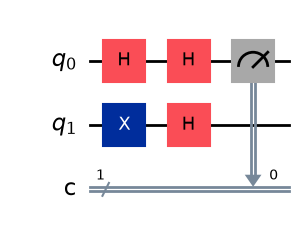

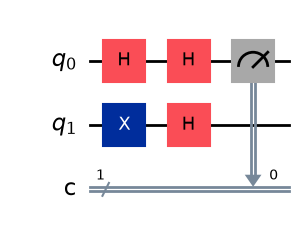

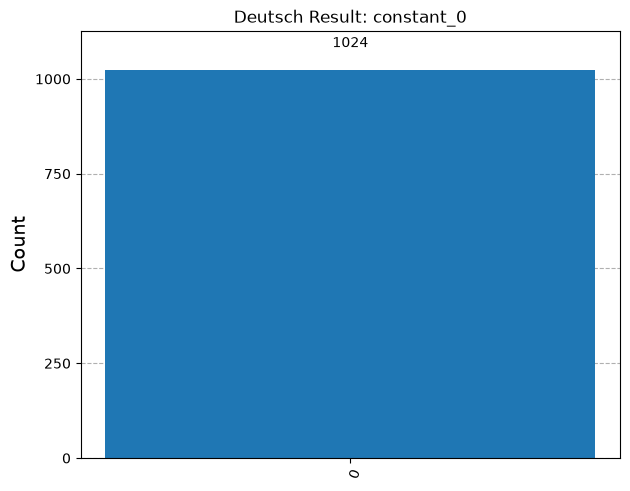

Counts: {'0': 1024}
Result: Function is CONSTANT

ORACLE: constant_1


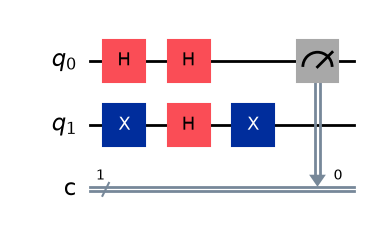

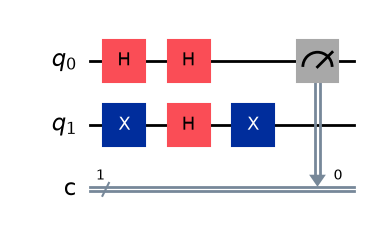

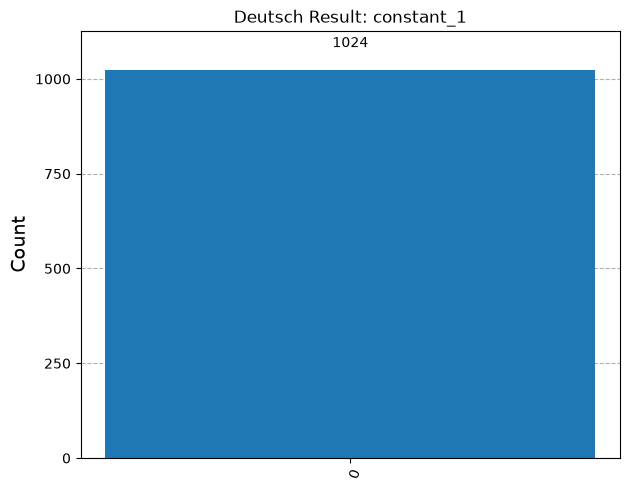

Counts: {'0': 1024}
Result: Function is CONSTANT

ORACLE: balanced_identity


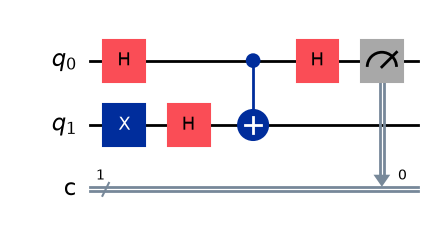

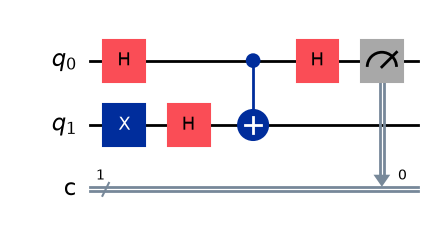

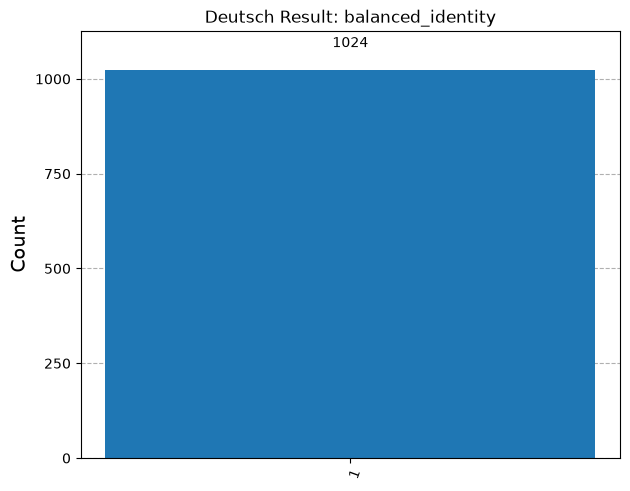

Counts: {'1': 1024}
Result: Function is BALANCED

ORACLE: balanced_not


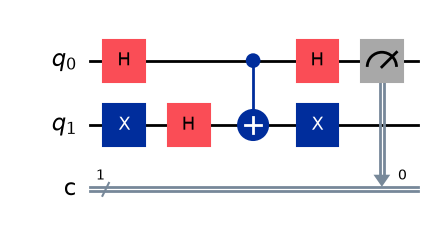

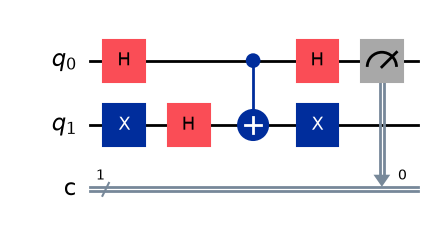

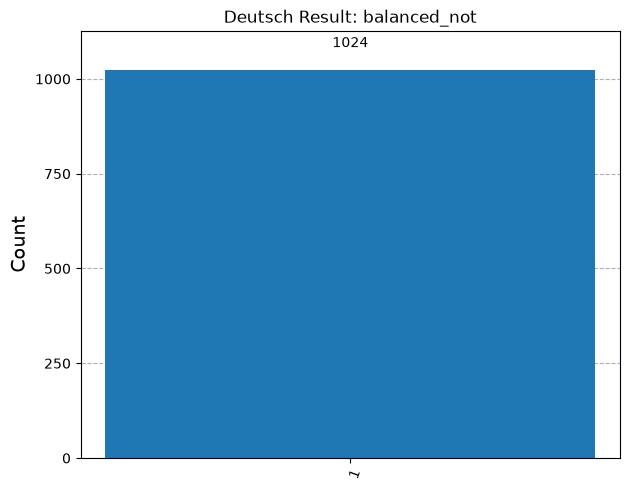

Counts: {'1': 1024}
Result: Function is BALANCED


In [1]:
# ======================================================
# FULL DEUTSCH LAB (1 Input Qubit)
# Four Boolean Functions: 2 Constant + 2 Balanced
# ======================================================

%matplotlib inline

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from matplotlib import pyplot as plt
from IPython.display import display

# ------------------------------------------------------
# Function to Build Deutsch Circuit (1 input qubit)
# ------------------------------------------------------
def deutsch_circuit(oracle_type="balanced_identity"):

    n = 1  # only 1 input qubit
    qc = QuantumCircuit(n+1, n)  # n input qubits + 1 ancilla

    # 1️⃣ Prepare ancilla in |->
    qc.x(n)
    qc.h(n)

    # 2️⃣ Create superposition on input qubit
    qc.h(0)

    # 3️⃣ Oracle
    if oracle_type == "constant_0":
        pass                 # f(x) = 0

    elif oracle_type == "constant_1":
        qc.x(n)              # f(x) = 1

    elif oracle_type == "balanced_identity":
        qc.cx(0, n)          # f(x) = x

    elif oracle_type == "balanced_not":
        qc.cx(0, n)
        qc.x(n)              # f(x) = 1 XOR x

    else:
        raise ValueError("Unknown oracle type")

    # 4️⃣ Interference
    qc.h(0)

    # 5️⃣ Measurement
    qc.measure(0, 0)

    return qc


# ======================================================
# SIMULATOR
# ======================================================

simulator = AerSimulator()

# ======================================================
# TEST ALL FOUR BOOLEAN FUNCTIONS
# ======================================================

oracle_types = [
    "constant_0",
    "constant_1",
    "balanced_identity",
    "balanced_not"
]

for oracle_type in oracle_types:

    print("\n====================================")
    print("ORACLE:", oracle_type)
    print("====================================")

    # Build quantum circuit
    qc = deutsch_circuit(oracle_type)

    # Display circuit
    display(qc.draw("mpl"))

    # Run simulation
    result = simulator.run(qc, shots=1024).result()

    # Get measurement counts
    counts = result.get_counts()

    # Display histogram
    plot_histogram(counts)
    plt.title("Deutsch Result: " + oracle_type)
    plt.show()

    # Display counts
    print("Counts:", counts)

    # Interpret measurement
    if max(counts, key=counts.get) == "0":
        print("Result: Function is CONSTANT")
    else:
        print("Result: Function is BALANCED")